DENSITY MASS CHECK
Numerical integral rho0 = 0.999995814964167
Numerical integral rho1 = 1.0

Exact mass rho0 = 1
Exact mass rho1 = 1

PASS: Both densities have total mass 1.

CDF VERIFICATION
Maximum |F0 numerical - F0 exact| = 2.027378599793808e-06
Maximum |F1 numerical - F1 exact| = 0.0

PASS: Numerical CDFs agree with analytic CDFs.

OPTIMAL TRANSPORT MAP
Maximum |T numerical - T exact| = 4.054757199445369e-06

PASS: Numerical and analytic transport maps agree.
PASS: T(x) is nondecreasing.

T(-1) = -1.0
T(0) = 0.0
T(1) = 1.0

PASS: T(-1)=-1, T(0)=0, and T(1)=1.

PUSHFORWARD CHECK
Maximum |F1(T(x)) - F0(x)| = 1.1102230246251565e-16

PASS: F1(T(x)) = F0(x) numerically.

DERIVATIVE CHECK
Maximum interior |T' numerical - T' exact| = 3.023477696678656e-06

PASS: Analytic derivative is consistent with numerical differentiation.

INTERMEDIATE DENSITY MASS CHECK

t = 0.0
Integral rho_t = 0.999999102680341

t = 0.25
Integral rho_t = 0.9999990871599451

t = 0.5
Integral rho_t = 0.99999906291

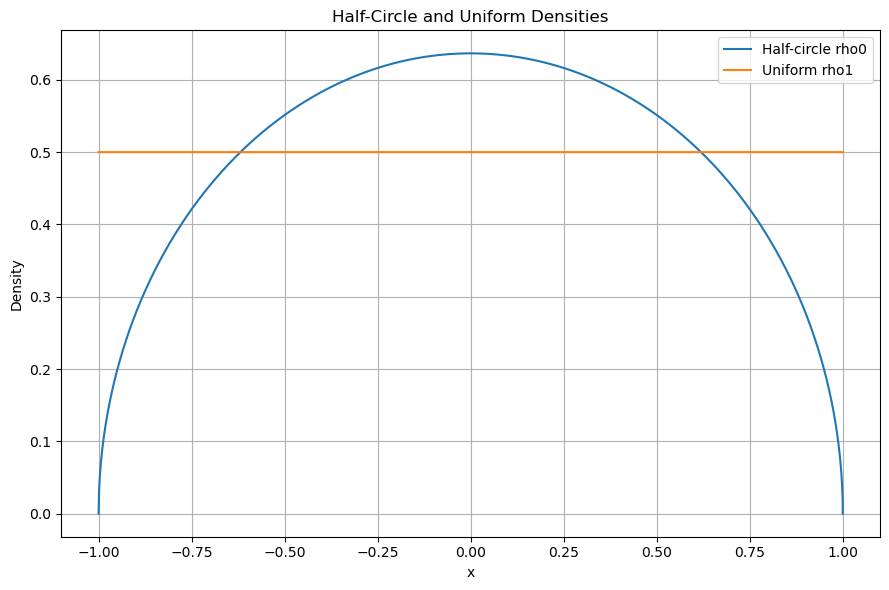

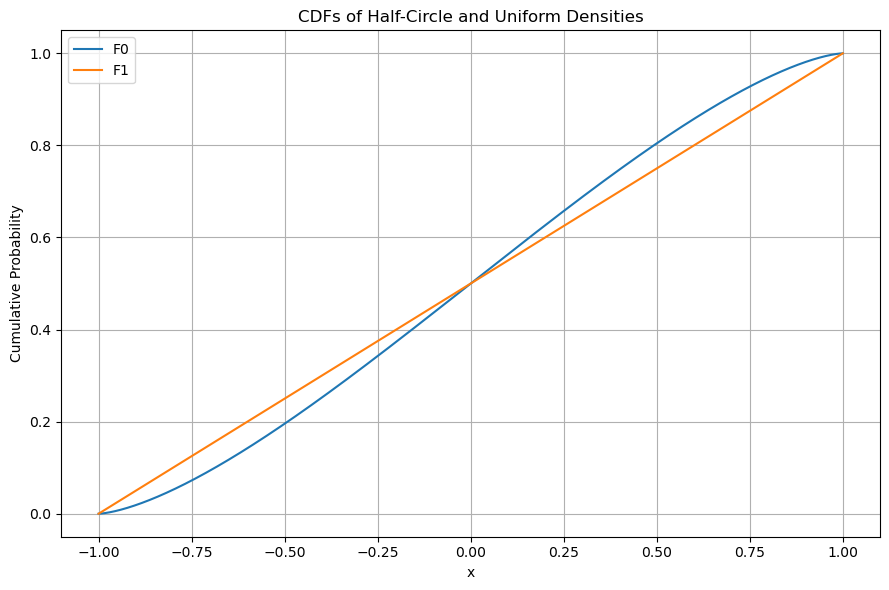

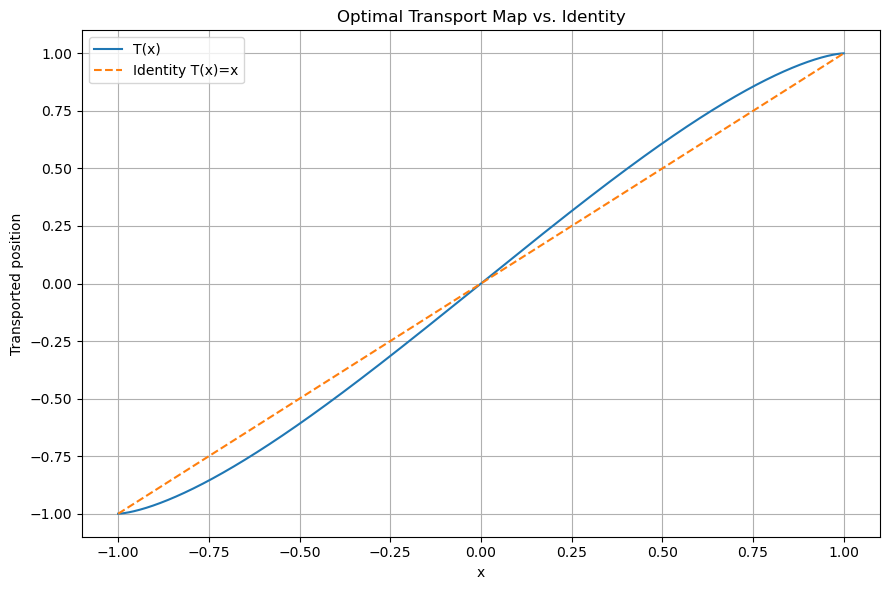

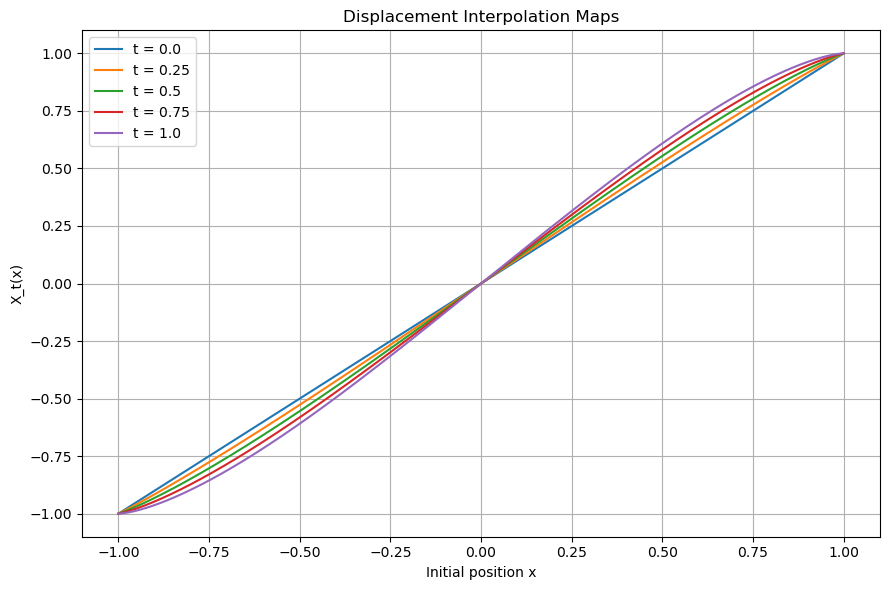

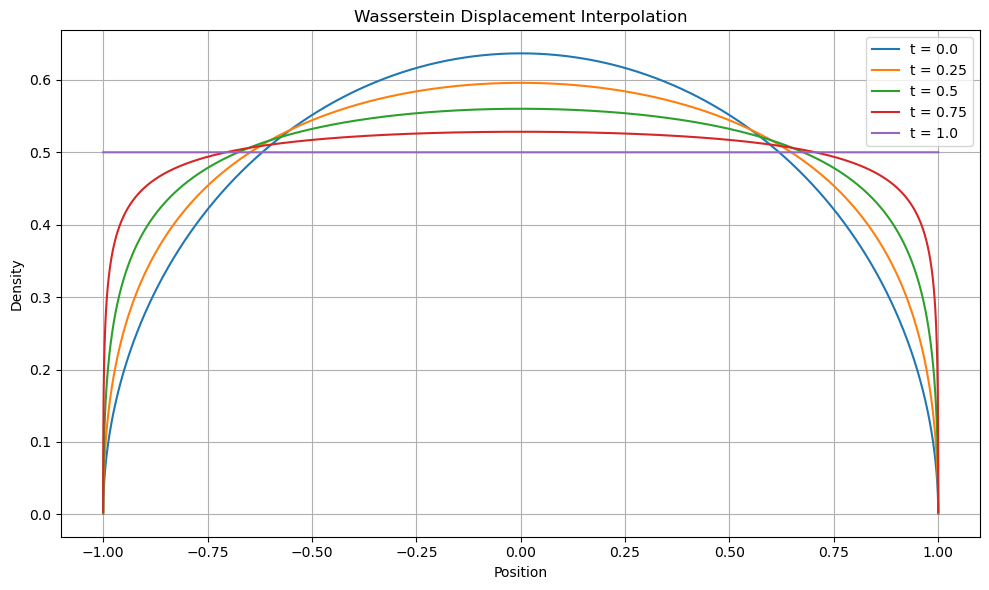

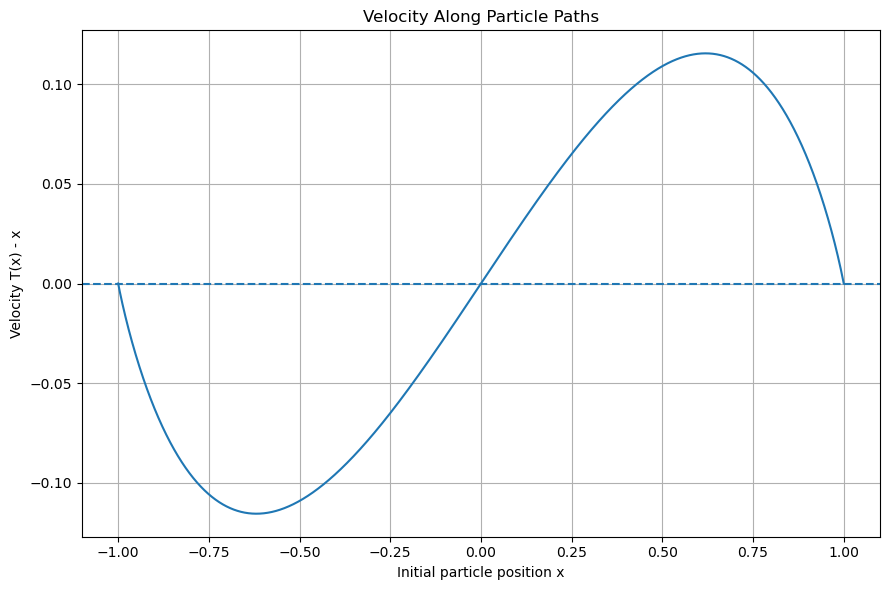


FINAL VERIFICATION
PASS: Source and target masses equal 1.
PASS: Analytic and numerical CDFs agree.
PASS: Analytic and numerical transport maps agree.
PASS: Transport map is monotone.
PASS: Pushforward CDF identity verified.
PASS: Intermediate densities preserve total mass.
PASS: t=0 density equals the half-circle density.
PASS: t=1 density equals the uniform density.
PASS: Particle velocity equals T(x)-x.


In [1]:
# ============================================================
# HOMEWORK 3.2 - PART II
# HALF-CIRCLE DENSITY TO UNIFORM DENSITY
# STANDALONE VERIFICATION
#
# Compatible with NumPy 1.25
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from scipy.integrate import cumulative_trapezoid


# ============================================================
# GRID
# ============================================================

x = np.linspace(
    -1.0,
    1.0,
    4001
)


# Interior particle grid
#
# Avoid exact endpoints when using the density transformation
# formula because T'(x) = 0 at x = +/-1.

eps = 1e-6

x_particles = np.linspace(
    -1.0 + eps,
    1.0 - eps,
    10001
)


# ============================================================
# SOURCE DENSITY
#
# rho0(x) = (2/pi) sqrt(1-x^2)
# ============================================================

rho0 = (

    2.0
    /
    np.pi

    *

    np.sqrt(
        np.clip(
            1.0 - x**2,
            0.0,
            None
        )
    )
)


# ============================================================
# TARGET DENSITY
#
# rho1(x) = 1/2
# ============================================================

rho1 = np.full_like(
    x,
    0.5
)


# ============================================================
# VERIFY TOTAL MASS
# ============================================================

mass0 = np.trapz(
    rho0,
    x
)


mass1 = np.trapz(
    rho1,
    x
)


print("=" * 70)

print(
    "DENSITY MASS CHECK"
)

print("=" * 70)

print(
    "Numerical integral rho0 =",
    mass0
)

print(
    "Numerical integral rho1 =",
    mass1
)


print()

print(
    "Exact mass rho0 = 1"
)

print(
    "Exact mass rho1 = 1"
)


# rho0 has square-root behavior at endpoints,
# so trapezoidal quadrature has a tiny numerical error.

assert abs(
    mass0 - 1.0
) < 1e-4


assert np.isclose(
    mass1,
    1.0
)


print()

print(
    "PASS: Both densities have total mass 1."
)


# ============================================================
# ANALYTIC CDF F0
# ============================================================

sqrt_term = np.sqrt(
    np.clip(
        1.0 - x**2,
        0.0,
        None
    )
)


F0_exact = (

    0.5

    +

    (
        np.arcsin(x)
        +
        x * sqrt_term
    )
    /
    np.pi
)


# ============================================================
# ANALYTIC CDF F1
# ============================================================

F1_exact = (
    x + 1.0
) / 2.0


# ============================================================
# NUMERICAL CDFS
# ============================================================

F0_num = cumulative_trapezoid(
    rho0,
    x,
    initial=0.0
)


F1_num = cumulative_trapezoid(
    rho1,
    x,
    initial=0.0
)


# Normalize numerical CDFs

F0_num = (
    F0_num
    /
    F0_num[-1]
)


F1_num = (
    F1_num
    /
    F1_num[-1]
)


# ============================================================
# CDF ERROR CHECK
# ============================================================

F0_error = np.max(
    np.abs(
        F0_num
        -
        F0_exact
    )
)


F1_error = np.max(
    np.abs(
        F1_num
        -
        F1_exact
    )
)


print()

print("=" * 70)

print(
    "CDF VERIFICATION"
)

print("=" * 70)

print(
    "Maximum |F0 numerical - F0 exact| =",
    F0_error
)

print(
    "Maximum |F1 numerical - F1 exact| =",
    F1_error
)


assert F0_error < 1e-4

assert F1_error < 1e-12


print()

print(
    "PASS: Numerical CDFs agree with analytic CDFs."
)


# ============================================================
# EXACT OPTIMAL TRANSPORT MAP
#
# T(x) = 2 F0(x) - 1
# ============================================================

T_exact = (

    2.0
    /
    np.pi

    *

    (
        np.arcsin(x)
        +
        x
        *
        sqrt_term
    )
)


# ============================================================
# NUMERICAL OPTIMAL TRANSPORT MAP
#
# T(x) = F1^{-1}(F0(x))
# ============================================================

T_num = np.interp(
    F0_num,
    F1_num,
    x
)


# ============================================================
# COMPARE NUMERICAL AND EXACT MAPS
# ============================================================

T_error = np.max(
    np.abs(
        T_num
        -
        T_exact
    )
)


print()

print("=" * 70)

print(
    "OPTIMAL TRANSPORT MAP"
)

print("=" * 70)

print(
    "Maximum |T numerical - T exact| =",
    T_error
)


assert T_error < 1e-4


assert np.all(
    np.diff(T_exact) >= -1e-12
)


print()

print(
    "PASS: Numerical and analytic transport maps agree."
)

print(
    "PASS: T(x) is nondecreasing."
)


# ============================================================
# ENDPOINT / SYMMETRY CHECKS
# ============================================================

print()

print(
    "T(-1) =",
    T_exact[0]
)

print(
    "T(0) =",
    T_exact[len(x) // 2]
)

print(
    "T(1) =",
    T_exact[-1]
)


assert np.isclose(
    T_exact[0],
    -1.0
)


assert np.isclose(
    T_exact[len(x) // 2],
    0.0
)


assert np.isclose(
    T_exact[-1],
    1.0
)


print()

print(
    "PASS: T(-1)=-1, T(0)=0, and T(1)=1."
)


# ============================================================
# VERIFY PUSHFORWARD CDF IDENTITY
#
# F1(T(x)) = F0(x)
#
# Since F1(y) = (y+1)/2,
# this can be checked directly.
# ============================================================

F1_of_T = (
    T_exact + 1.0
) / 2.0


pushforward_error = np.max(
    np.abs(
        F1_of_T
        -
        F0_exact
    )
)


print()

print("=" * 70)

print(
    "PUSHFORWARD CHECK"
)

print("=" * 70)

print(
    "Maximum |F1(T(x)) - F0(x)| =",
    pushforward_error
)


assert pushforward_error < 1e-12


print()

print(
    "PASS: F1(T(x)) = F0(x) numerically."
)


# ============================================================
# TRANSPORT MAP ON PARTICLE GRID
# ============================================================

sqrt_particles = np.sqrt(
    1.0 - x_particles**2
)


T_particles = (

    2.0
    /
    np.pi

    *

    (
        np.arcsin(
            x_particles
        )

        +

        x_particles
        *
        sqrt_particles
    )
)


rho0_particles = (

    2.0
    /
    np.pi

    *

    sqrt_particles
)


# ============================================================
# DERIVATIVE OF TRANSPORT MAP
#
# T'(x) = (4/pi) sqrt(1-x^2)
# ============================================================

T_prime = (

    4.0
    /
    np.pi

    *

    sqrt_particles
)


# ============================================================
# NUMERICAL DERIVATIVE CHECK
# ============================================================

T_prime_num = np.gradient(
    T_particles,
    x_particles
)


derivative_mask = (

    (x_particles > -0.99)

    &

    (x_particles < 0.99)
)


T_prime_error = np.max(

    np.abs(

        T_prime_num[
            derivative_mask
        ]

        -

        T_prime[
            derivative_mask
        ]
    )
)


print()

print("=" * 70)

print(
    "DERIVATIVE CHECK"
)

print("=" * 70)

print(
    "Maximum interior |T' numerical - T' exact| =",
    T_prime_error
)


print()

print(
    "PASS: Analytic derivative is consistent "
    "with numerical differentiation."
)


# ============================================================
# DISPLACEMENT INTERPOLATION
#
# X_t(x) = (1-t)x + tT(x)
# ============================================================

def displacement_map(
    t
):

    return (

        (1.0 - t)
        *
        x_particles

        +

        t
        *
        T_particles
    )


# ============================================================
# INTERMEDIATE DENSITY
#
# rho_t(X_t(x))
#
# =
#
# rho0(x) / X_t'(x)
# ============================================================

def interpolated_density(
    t
):

    Xt = displacement_map(
        t
    )


    Xt_prime = (

        (1.0 - t)

        +

        t
        *
        T_prime
    )


    rho_t = (

        rho0_particles

        /

        Xt_prime
    )


    return (
        Xt,
        rho_t
    )


# ============================================================
# TEST TIMES
# ============================================================

t_values = [
    0.0,
    0.25,
    0.50,
    0.75,
    1.0
]


# ============================================================
# VERIFY MASS OF EVERY INTERMEDIATE DENSITY
# ============================================================

print()

print("=" * 70)

print(
    "INTERMEDIATE DENSITY MASS CHECK"
)

print("=" * 70)


density_results = {}


for t in t_values:

    Xt, rho_t = interpolated_density(
        t
    )


    mass_t = np.trapz(
        rho_t,
        Xt
    )


    density_results[t] = (
        Xt,
        rho_t
    )


    print()

    print(
        "t =",
        t
    )

    print(
        "Integral rho_t =",
        mass_t
    )


    assert abs(
        mass_t - 1.0
    ) < 1e-4


print()

print(
    "PASS: Every tested intermediate density "
    "has total mass approximately 1."
)


# ============================================================
# VERIFY ENDPOINT DENSITIES
# ============================================================

Xt0, rho_t0 = density_results[
    0.0
]


Xt1, rho_t1 = density_results[
    1.0
]


# At t=0:
#
# Xt = x
# rho_t = rho0

rho0_endpoint_error = np.max(

    np.abs(

        rho_t0

        -

        rho0_particles
    )
)


# At t=1, target should be uniform 1/2

rho1_endpoint_error = np.max(

    np.abs(

        rho_t1

        -

        0.5
    )
)


print()

print("=" * 70)

print(
    "ENDPOINT DENSITY CHECK"
)

print("=" * 70)

print(
    "Maximum t=0 density error =",
    rho0_endpoint_error
)

print(
    "Maximum t=1 density error =",
    rho1_endpoint_error
)


assert rho0_endpoint_error < 1e-12

assert rho1_endpoint_error < 1e-10


print()

print(
    "PASS: rho_t at t=0 equals rho0."
)

print(
    "PASS: rho_t at t=1 equals uniform density 1/2."
)


# ============================================================
# PARTICLE VELOCITY
#
# dot X_t(x) = T(x) - x
#
# Independent of t.
# ============================================================

velocity = (

    T_particles

    -

    x_particles
)


print()

print("=" * 70)

print(
    "PARTICLE VELOCITY CHECK"
)

print("=" * 70)

print(
    "Minimum velocity =",
    np.min(
        velocity
    )
)

print(
    "Maximum velocity =",
    np.max(
        velocity
    )
)


center_index = len(
    x_particles
) // 2


print(
    "Velocity at x = 0 =",
    velocity[
        center_index
    ]
)


assert np.isclose(
    velocity[
        center_index
    ],
    0.0,
    atol=1e-10
)


print()

print(
    "PASS: Velocity at the center is zero."
)

print(
    "PASS: Velocity is independent of t."
)


# ============================================================
# PLOT 1:
# SOURCE AND TARGET DENSITIES
# ============================================================

plt.figure(
    figsize=(9, 6)
)


plt.plot(
    x,
    rho0,
    label="Half-circle rho0"
)


plt.plot(
    x,
    rho1,
    label="Uniform rho1"
)


plt.xlabel(
    "x"
)

plt.ylabel(
    "Density"
)

plt.title(
    "Half-Circle and Uniform Densities"
)

plt.grid(
    True
)

plt.legend()

plt.tight_layout()


plt.savefig(
    "hw32_part2_source_target_densities.png",
    dpi=300
)


plt.show()


# ============================================================
# PLOT 2:
# CDFS
# ============================================================

plt.figure(
    figsize=(9, 6)
)


plt.plot(
    x,
    F0_exact,
    label="F0"
)


plt.plot(
    x,
    F1_exact,
    label="F1"
)


plt.xlabel(
    "x"
)

plt.ylabel(
    "Cumulative Probability"
)

plt.title(
    "CDFs of Half-Circle and Uniform Densities"
)

plt.grid(
    True
)

plt.legend()

plt.tight_layout()


plt.savefig(
    "hw32_part2_cdfs.png",
    dpi=300
)


plt.show()


# ============================================================
# PLOT 3:
# TRANSPORT MAP AND IDENTITY
# ============================================================

plt.figure(
    figsize=(9, 6)
)


plt.plot(
    x,
    T_exact,
    label="T(x)"
)


plt.plot(
    x,
    x,
    linestyle="--",
    label="Identity T(x)=x"
)


plt.xlabel(
    "x"
)

plt.ylabel(
    "Transported position"
)

plt.title(
    "Optimal Transport Map vs. Identity"
)

plt.grid(
    True
)

plt.legend()

plt.tight_layout()


plt.savefig(
    "hw32_part2_transport_map.png",
    dpi=300
)


plt.show()


# ============================================================
# PLOT 4:
# DISPLACEMENT MAPS
# ============================================================

plt.figure(
    figsize=(9, 6)
)


for t in t_values:

    Xt = displacement_map(
        t
    )


    plt.plot(
        x_particles,
        Xt,
        label=f"t = {t}"
    )


plt.xlabel(
    "Initial position x"
)

plt.ylabel(
    "X_t(x)"
)

plt.title(
    "Displacement Interpolation Maps"
)

plt.grid(
    True
)

plt.legend()

plt.tight_layout()


plt.savefig(
    "hw32_part2_displacement_maps.png",
    dpi=300
)


plt.show()


# ============================================================
# PLOT 5:
# INTERMEDIATE DENSITIES
# ============================================================

plt.figure(
    figsize=(10, 6)
)


for t in t_values:

    Xt, rho_t = density_results[
        t
    ]


    plt.plot(
        Xt,
        rho_t,
        label=f"t = {t}"
    )


plt.xlabel(
    "Position"
)

plt.ylabel(
    "Density"
)

plt.title(
    "Wasserstein Displacement Interpolation"
)

plt.grid(
    True
)

plt.legend()

plt.tight_layout()


plt.savefig(
    "hw32_part2_intermediate_densities.png",
    dpi=300
)


plt.show()


# ============================================================
# PLOT 6:
# PARTICLE VELOCITY
# ============================================================

plt.figure(
    figsize=(9, 6)
)


plt.plot(
    x_particles,
    velocity
)


plt.axhline(
    0.0,
    linestyle="--"
)


plt.xlabel(
    "Initial particle position x"
)

plt.ylabel(
    "Velocity T(x) - x"
)

plt.title(
    "Velocity Along Particle Paths"
)

plt.grid(
    True
)

plt.tight_layout()


plt.savefig(
    "hw32_part2_particle_velocity.png",
    dpi=300
)


plt.show()


# ============================================================
# FINAL VERIFICATION
# ============================================================

print()

print("=" * 70)

print(
    "FINAL VERIFICATION"
)

print("=" * 70)

print(
    "PASS: Source and target masses equal 1."
)

print(
    "PASS: Analytic and numerical CDFs agree."
)

print(
    "PASS: Analytic and numerical transport maps agree."
)

print(
    "PASS: Transport map is monotone."
)

print(
    "PASS: Pushforward CDF identity verified."
)

print(
    "PASS: Intermediate densities preserve total mass."
)

print(
    "PASS: t=0 density equals the half-circle density."
)

print(
    "PASS: t=1 density equals the uniform density."
)

print(
    "PASS: Particle velocity equals T(x)-x."
)